<a href="https://colab.research.google.com/github/yufree/OSSpRe/blob/main/OSSpRe_colab_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OSSpRe 修复验证 notebook (Colab / Linux, renv 环境恢复)

本 notebook 在 Linux 上验证 OSSpRe 的全部修复。环境完全按仓库自带的
`renv.lock` 恢复(R 4.6.1,178 个包;`opentimsr` 从作者 drat 仓库的 vendored
版本恢复,规避上游 GitHub monorepo symlink 问题)。

**不依赖 rpy2** —— 所有 R 逻辑通过 `Rscript` 执行,不存在嵌入式 R 初始化
崩溃问题。

流程:

1. 安装系统库 + Posit r-builds 的 **R 4.6.1**(与 `renv.lock` 一致)
2. 从 GitHub 克隆仓库(main 分支,修复已合入),验证标记 + drat 兜底
3. `renv::restore()` 恢复全部 R 包(CRAN 走 P3M 二进制;Bioconductor 3.23 的
   42 个包源码编译,**全程最慢,约 30–50 分钟**)
4. 运行测试脚本:编译 4 个 C++ → `findpeakalign` 正确性/性能 → `find_2d_peaks`
   种峰回收+并发确定性 → Bruker 库 1/k0↔CCS 往返 → `helper.r` 端到端
5. 汇总 PASS/FAIL/SKIP 报告

**使用方法**: 直接在 Colab 打开:
`https://colab.research.google.com/github/yufree/OSSpRe/blob/main/OSSpRe_colab_test.ipynb`
默认 CPU 运行时即可,**全程约 40–60 分钟**,期间保持标签页打开。

In [9]:
%%bash
# ---- 系统库 + renv.lock 指定的 R 4.6.1 (Posit r-builds, 约 3 分钟) ----
set -e
apt-get update -qq
PKGS="build-essential gfortran git curl ca-certificates \
  libcurl4-openssl-dev libssl-dev libxml2-dev libzstd-dev \
  libfontconfig1-dev libfreetype6-dev pkg-config libpng-dev libtiff-dev \
  libjpeg-dev libnetcdf-dev libgit2-dev libglpk-dev libharfbuzz-dev \
  libfribidi-dev libcairo2-dev libxt-dev libblas-dev liblapack-dev"
DEBIAN_FRONTEND=noninteractive apt-get install -y --no-install-recommends $PKGS \
  > /tmp/apt.log 2>&1 || { echo "部分系统包安装失败, 继续尝试..."; tail -5 /tmp/apt.log; }

. /etc/os-release
case "$VERSION_CODENAME" in
  noble) UB=2404 ;;
  *)     UB=2204 ;;
esac
echo "$VERSION_CODENAME" > /content/codename
echo "Ubuntu $VERSION_CODENAME -> ubuntu-$UB}"
if curl -fsSL -o /tmp/r.deb "https://cdn.posit.co/r/ubuntu-${UB}/pkgs/r-4.6.1_1_amd64.deb" \
   && DEBIAN_FRONTEND=noninteractive apt-get install -y /tmp/r.deb >> /tmp/apt.log 2>&1; then
  ln -sf /opt/R/4.6.1/bin/R /usr/local/bin/R
  ln -sf /opt/R/4.6.1/bin/Rscript /usr/local/bin/Rscript
  echo "已安装 r-builds R 4.6.1 (与 renv.lock 一致)"
else
  echo "警告: r-builds 安装失败, 回退 apt r-base (版本可能与锁文件不符)"
  DEBIAN_FRONTEND=noninteractive apt-get install -y r-base r-base-dev >> /tmp/apt.log 2>&1
fi
R --version | head -1
nproc

Ubuntu noble -> ubuntu-2404}
已安装 r-builds R 4.6.1 (与 renv.lock 一致)
R version 4.6.1 (2026-06-24) -- "Happy Hop"
2


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


## 1. 克隆仓库并验证修复已包含

修复已合入 GitHub main(≥ `79cb81b` 代码修复、`db86bf8` drat 环境修复)。
克隆后验证标记存在;若 `renv.lock` 仍是旧版(理论上不会),自动切换 opentimsr 到 drat。

In [2]:
%%bash
set -e
cd /content
rm -rf OSSpRe
git clone --depth 1 https://github.com/yufree/OSSpRe.git
cd OSSpRe
git log --oneline -1
grep -q "roi_idx" helper.r \
  && echo "代码修复已包含 (>= 79cb81b)" \
  || { echo "错误: 克隆的仓库缺少修复"; exit 1; }
grep -q 'yufree.github.io/drat' renv.lock && echo "renv.lock 已指向 drat" || python3 - <<'PYEOF'
import json
lock = json.load(open('renv.lock'))
p = lock['Packages'].get('opentimsr')
if p:
    lock['Packages']['opentimsr'] = {k: v for k, v in p.items()
                                     if not k.startswith(('Remote', 'Github'))}
    lock['Packages']['opentimsr']['Source'] = 'Repository'
    repos = lock['R']['Repositories']
    if not any(r['Name'] == 'drat' for r in repos):
        repos.append({'Name': 'drat', 'URL': 'https://yufree.github.io/drat'})
    json.dump(lock, open('renv.lock', 'w'), indent=2, ensure_ascii=False)
    print('renv.lock: opentimsr 记录已切换到 drat')
PYEOF
echo "克隆就绪"

4363084 Rebuild Colab test notebook without rpy2 (Rscript-based, fixes embedded-R segfault on load) and fix test ordering/density issues found in full local run
代码修复已包含 (>= 79cb81b)
renv.lock 已指向 drat
克隆就绪


Cloning into 'OSSpRe'...


## 2. `renv::restore()` 按锁文件恢复 R 环境 (约 30–50 分钟)

- 178 个包:134 个 CRAN 包走 Posit P3M **二进制**(分钟级);42 个 Bioconductor 3.23
  包无二进制可用,从**源码编译**(mzR/MSnbase/xcms 较慢,全程最耗时的一步)
- `pmd` / `rmwf` 按锁文件 Remote 字段从 **GitHub** tarball 恢复
- `opentimsr` 从 **drat 仓库**(https://yufree.github.io/drat)恢复 vendored 版本
- 个别包版本若已在 CRAN 更新,自动回退 cloud.r-project.org 的 Archive 归档

中断(断连/网络抖动)后**直接重跑本单元格**即可,renv 只补缺失的包。

In [16]:
%%writefile /content/setup_env.R
# 按 renv.lock 恢复环境 (独立 R 进程, 无需 rpy2)
# 在加载 renv 之前配置环境变量，以强制从源码编译二进制受损的包
Sys.setenv(RENV_CONFIG_TYPE = "source")
options(renv.config.type = "source")

codename <- tryCatch(readLines("/content/codename", warn = FALSE), error = function(e) "jammy")
repos <- c(P3Mbin  = sprintf("https://packagemanager.posit.co/all/__linux__/%s/latest", codename),
           drat    = "https://yufree.github.io/drat",
           CRAN    = "https://cloud.r-project.org",
           BioCsoft = "https://bioconductor.org/packages/3.23/bioc")
options(repos = repos)
if (!requireNamespace("renv", quietly = TRUE)) install.packages("renv", repos = repos[1])

setwd("/content/OSSpRe")
source("renv/activate.R")
cat("R:", as.character(getRversion()), "| 项目库:", unlist(.libPaths())[1], "\n")

t0 <- Sys.time()
# 显式从源码重建并安装 stringi，绕过任何损坏的 binary 缓存
cat("正在从源码编译安装 stringi...\n")
try(renv::install("stringi", rebuild = TRUE, prompt = FALSE))

# 运行常规 restore
renv::restore(prompt = FALSE, repos = repos)
cat(sprintf("renv::restore 完成, 耗时 %.1f 分钟\n",
            as.numeric(difftime(Sys.time(), t0, units = "mins"))))

need <- c("Rcpp", "data.table", "opentimsr", "pmd", "rmwf", "enviGCMS", "irlba", "ClusterR")
got <- sapply(need, requireNamespace, quietly = TRUE)
print(got)
stopifnot(all(got))
cat("环境就绪\n")

Overwriting /content/setup_env.R


In [17]:
%%bash
# 约 30-50 分钟 (Bioconductor 源码编译); 中断后重跑本单元格即可续传
# 强制安装 R 编译所需的系统级依赖项 (如 libglpk-dev)
sudo apt-get update -qq && sudo apt-get install -y --no-install-recommends libglpk-dev libgmp3-dev libuv1-dev
export RENV_CONFIG_INSTALL_TRANSACTIONAL=FALSE
Rscript /content/setup_env.R

Reading package lists...
Building dependency tree...
Reading state information...
libglpk-dev is already the newest version (5.0-1build2).
libgmp3-dev is already the newest version (2:6.3.0+dfsg-2ubuntu6.1).
libuv1-dev is already the newest version (1.48.0-1.1build1).
0 upgraded, 0 newly installed, 0 to remove and 53 not upgraded.
- One or more packages recorded in the lockfile are not installed.
- Use `renv::status()` for more details.
R: 4.6.1 | 项目库: /content/OSSpRe/renv/library/linux-ubuntu-noble/R-4.6/x86_64-pc-linux-gnu 
正在从源码编译安装 stringi...
- Querying repositories for available source packages ... Done!
The following package(s) will be installed:
- stringi [1.8.9]
These packages will be installed into "/content/OSSpRe/renv/library/linux-ubuntu-noble/R-4.6/x86_64-pc-linux-gnu".

# Downloading packages -------------------------------------------------------
✔ stringi 1.8.9                            [3.5 MB in 0.57s]
Successfully downloaded 1 package in 1 second.

# Installing pack

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Warning message:
In file(con, "r") :
  cannot open file '/content/codename': No such file or directory


## 3. 运行全部测试 (约 2–5 分钟)

覆盖:C++ 编译(Linux/gcc/OpenMP)、`findpeakalign` 与暴力参考实现逐行对比 + 边缘
情况 + 性能基准、`find_2d_peaks` 种峰回收 + OpenMP 并发确定性、Bruker 库
1/k0↔CCS 往返(下载失败自动 SKIP)、`helper.r` 端到端(PCA 分割维度、np 计数、
ROI 聚类 NaN 防护、注释、空网络保护、签名)。

In [20]:
%%writefile /content/run_tests.R
# OSSpRe 修复验证 (独立 R 进程; 状态通过文件传递)
setwd("/content/OSSpRe")
source("renv/activate.R")   # 使用已恢复的项目库
pdf(NULL)                   # 屏蔽交互绘图设备, 显式 png() 不受影响

RESULTS <- new.env()
check <- function(name, expr) {
  ok <- tryCatch(isTRUE(force(expr)),
                 error = function(e) {
                   cat("  ERROR:", conditionMessage(e), "\n")
                   FALSE
                 })
  RESULTS[[name]] <- ok
  cat(sprintf("[%s] %s\n", if (ok) "PASS" else "FAIL", name))
  invisible(ok)
}

## ---- S1: 编译 4 个 C++ 文件 ----
check("cpp_one_over_k0_compiles", { library(Rcpp); sourceCpp("one_over_k0_to_ccs.cpp"); TRUE })
check("cpp_ccs_to_k0_compiles",   { sourceCpp("ccs_to_one_over_k0.cpp"); TRUE })
check("cpp_peakalign_compiles",   { sourceCpp("peakalign.cpp"); TRUE })
check("cpp_peakfinder_compiles",  { sourceCpp("peak_finder.cpp"); TRUE })

# helper.r 中的 R 包装器(提前定义供 S3 使用; 与 helper.r 定义一致, 后者稍后重定义无碍)
find_2d_peaks <- function(mz, ccs, intensity, mz_ppm = 20, ccs_tolerance = 0.03,
                          snr = 3.0, mz_bins = 1000, ccs_bins = 50) {
  if (!is.numeric(mz) || !is.numeric(ccs) || !is.numeric(intensity))
    stop("All inputs must be numeric vectors")
  if (length(mz) != length(ccs) || length(mz) != length(intensity))
    stop("All input vectors must have the same length")
  find_2d_peaks_spatial_parallel_openmp(mz, ccs, intensity,
                                        mz_ppm, ccs_tolerance, snr, mz_bins, ccs_bins)
}

## ---- S2: findpeakalign 正确性 + 性能 ----
set.seed(123)
n <- 4000
frame <- sample(1:3, n, replace = TRUE)
mz <- round(runif(n, 700, 800), 4)
ccs <- round(runif(n, 250, 320), 2)
intensity <- round(runif(n) * 1000, 1)
ref_mz <- c(710.05, 725.5, 733.33, 748.9, 760.02, 775.6, 790.123, 799.999)
ref_ccs <- c(280.1, 290.5, 300.2, 265.0, 310.3, 275.8, 295.4, 305.9)
ppm <- 20; ccs_shift <- 0.03

ref_impl <- function() {
  out <- data.frame(frame = integer(), mz_ccs = character(), intensity = double())
  for (i in seq_along(ref_mz)) {
    mz_tol <- ppm * ref_mz[i] / 1e6; ccs_tol <- ccs_shift * ref_ccs[i]
    key <- paste0(sprintf("%.6f", ref_mz[i]), "_", sprintf("%.6f", ref_ccs[i]))
    for (f in sort(unique(frame))) {
      j <- which(frame == f)
      hit <- abs(mz[j] - ref_mz[i]) <= mz_tol & abs(ccs[j] - ref_ccs[i]) <= ccs_tol
      tot <- sum(intensity[j][hit])
      if (tot > 0) out <- rbind(out, data.frame(frame = f, mz_ccs = key, intensity = tot))
    }
  }
  out
}
r_new <- as.data.frame(findpeakalign(mz, ccs, intensity, frame, ref_mz, ref_ccs, ppm, ccs_shift))
r_ref <- ref_impl()
a <- r_new[order(r_new$frame, r_new$mz_ccs), ]; b <- r_ref[order(r_ref$frame, r_ref$mz_ccs), ]
check("align_matches_reference", nrow(a) == nrow(b) && identical(a$frame, b$frame) &&
        identical(a$mz_ccs, b$mz_ccs) && max(abs(a$intensity - b$intensity)) == 0)

e <- findpeakalign(numeric(0), numeric(0), numeric(0), integer(0), ref_mz, ref_ccs, ppm, ccs_shift)
z <- findpeakalign(mz, ccs, intensity, frame, 999.9, 200, ppm, ccs_shift)
check("align_edgecases", nrow(e) == 0 && nrow(z) == 0)

for (nn in c(2e4, 1e5, 5e5)) {
  mz2 <- round(runif(nn, 700, 800), 4); ccs2 <- round(runif(nn, 250, 320), 2)
  int2 <- runif(nn); fr2 <- sample(1:500, nn, replace = TRUE)
  rmz <- round(runif(500, 700, 800), 4); rccs <- runif(500, 250, 320)
  t0 <- Sys.time()
  res <- findpeakalign(mz2, ccs2, int2, fr2, rmz, rccs, ppm, ccs_shift)
  cat(sprintf("  %d 点 x 500 参考峰 x 500 帧: %.3f 秒 (%d 行命中)\n",
              nn, as.numeric(difftime(Sys.time(), t0, units = "secs")), nrow(res)))
}
t0 <- Sys.time(); invisible(ref_impl())
cat(sprintf("  [对照] R 暴力参考实现仅 %d 点 x 8 峰 x 3 帧就耗时 %.1f 秒\n",
            n, as.numeric(difftime(Sys.time(), t0, units = "secs"))))
check("align_benchmark_runs", TRUE)

## ---- S3: find_2d_peaks 种峰回收 + 并发确定性 ----
set.seed(1)
n_bg <- 20000
mzp <- runif(n_bg, 748, 752); ccsp <- runif(n_bg, 280, 300); intp <- runif(n_bg, 1, 100)
centers <- data.frame(mz = seq(748.4, 751.6, length.out = 5), ccs = 290)
for (i in 1:5) {
  mzp <- c(mzp, centers$mz[i] + rnorm(30, 0, centers$mz[i] * 5e-6))
  ccsp <- c(ccsp, centers$ccs[i] + rnorm(30, 0, centers$ccs[i] * 0.005))
  intp <- c(intp, c(10000, runif(29, 5000, 9999)))
}
res2 <- find_2d_peaks(mzp, ccsp, intp, mz_ppm = 20, ccs_tolerance = 0.03, snr = 3,
                      mz_bins = 1000, ccs_bins = 50)
found <- sapply(1:5, function(i)
  any(abs(res2$mz - centers$mz[i]) <= centers$mz[i] * 50e-6 &
      abs(res2$ccs - centers$ccs[i]) <= centers$ccs[i] * 0.05))
cat("  找到峰数:", nrow(res2), "(背景应被 SNR 滤除) 5个种峰全部回收:", all(found), "\n")
check("peakfinder_recovers_planted", nrow(res2) <= 10 && all(found))

r5 <- replicate(5, find_2d_peaks(mzp, ccsp, intp, 20, 0.03, 3, 1000, 50), simplify = FALSE)
check("peakfinder_deterministic_openmp", all(sapply(r5[-1], function(x) identical(x, r5[[1]]))))

d <- find_2d_peaks(rep(700.5, 10), rep(280, 10), 1:10, 20, 0.03, 3, 100, 50)
check("peakfinder_degenerate_input", nrow(d) >= 1 && !any(is.na(d$ccs)))

## ---- S4: Bruker 库往返 (可选, 下载失败自动 SKIP) ----
lib <- tryCatch(opentimsr::download_bruker_proprietary_code("/content/bruker"),
               error = function(e) NULL)
if (is.null(lib) || !file.exists("/content/bruker/libtimsdata.so")) {
  RESULTS[["bruker_roundtrip"]] <- NA
  cat("[SKIP] bruker_roundtrip (Bruker 库下载不可用)\n")
} else {
  cat("Bruker 库:", lib, "\n")
  check("bruker_roundtrip", {
    k0 <- seq(0.6, 1.6, length.out = 50); mzv <- seq(200, 1000, length.out = 50)
    ccs3 <- one_over_k0_to_ccs_parallel(k0, rep(1, 50), mzv, lib)
    k0b <- ccs_to_one_over_k0_parallel(ccs3, rep(1, 50), mzv, lib)
    max(abs(k0 - k0b)) < 1e-4 &&
      is.finite(sum(one_over_k0_to_ccs_parallel(k0, rep(1, 50), mzv, lib)))
  })
}

## ---- S5: helper.r 端到端 ----
t0 <- Sys.time()
suppressPackageStartupMessages(source("helper.r"))
cat(sprintf("helper.r 加载完成 (%.1fs)\n", as.numeric(difftime(Sys.time(), t0, units = "secs"))))

set.seed(42)
n_pix <- 200; n_ion <- 60
xs <- rep(1:20, each = 10) * 10; ys <- rep(1:10, 20) * 10
mzv <- round(seq(700, 900, length.out = n_ion), 4)
imv <- round(seq(250, 320, length.out = n_ion), 2)
M <- sapply(seq_len(n_ion), function(i) {
  if (i <= 20) as.numeric(xs + rnorm(n_pix, 0, .3))
  else if (i <= 40) as.numeric(ys + rnorm(n_pix, 0, .3))
  else rep(0, n_pix)
})
dt <- data.table(location = paste0(xs, "_", ys), M)
colnames(dt) <- c("location", paste0(mzv, "_", imv))
csv <- "test_ticmzccs.csv"; fwrite(dt, csv)

s <- capture.output(getsummary(csv))
check("helper_getsummary", any(grepl("m/z range", s)))

invisible(capture.output(plot_peak_stats(csv)))
d2 <- fread(csv)
np_fn <- d2[, rowSums(.SD != 0), .SDcols = -1]
np_manual <- rowSums(as.matrix(d2[, -1]) != 0)
check("helper_np_counts_correct", isTRUE(all.equal(np_fn, np_manual)))

invisible(capture.output(perform_pca_segmentation(csv, "test_seg.csv")))
seg <- fread("test_seg.csv")
check("helper_pca_clusters_pixels", nrow(seg) == n_pix && length(unique(seg$seg)) >= 2)

perform_reactomics_analysis(csv, "test_react.csv")
rr <- fread("test_react.csv")
check("helper_reactomics_structure", nrow(rr) == n_pix && ncol(rr) == 2 + 3 * 4)

locindex <- rep(c(TRUE, FALSE), each = n_pix / 2)
okc <- tryCatch({
  suppressWarnings(perform_cluster_ions(csv, "test_ioncluster.csv", locindex = locindex,
                                        hclust_cutoff = 0.6, min_cluster_size = 3,
                                        folder_name = "test_cluster"))
  TRUE
}, error = function(e) { cat("  错误:", conditionMessage(e), "\n"); FALSE })
ic <- if (file.exists("test_ioncluster.csv")) fread("test_ioncluster.csv") else data.table()
check("helper_cluster_roi_no_nan_crash", okc && nrow(ic) == n_ion)

sel <- fread("lipidall.csv")[adducts %in% c("[M+H]", "[M+Na]")][1:5]
dt6 <- data.table(location = paste0(xs, "_", ys), matrix(runif(n_pix * 5), nrow = n_pix))
colnames(dt6) <- c("location", paste0(sel$mz, "_", sel$ccs))
fwrite(dt6, "test_peak5.csv")
getanno(database = "lipidall.csv", mode = "pos", peakpath = "test_peak5.csv", annofile = "test_anno.csv")
check("helper_getanno", nrow(fread("test_anno.csv")) >= 5)

fwrite(data.frame(name = character(), mz = numeric()), "test_emptyanno.csv")
okn <- tryCatch({
  generate_molecular_network(csv, "test_ioncluster.csv", "test_emptyanno.csv", "test_net.csv"); TRUE
}, error = function(e) FALSE)
check("helper_network_empty_guard", okn && nrow(fread("test_net.csv")) == 0)

fg <- formals(getqlist); fr <- formals(getrefpeak)
check("helper_signatures", all(c("mz_ppm", "ccs_tolerance") %in% names(fg)) &&
        identical(fr$libpath, "./") && !exists("perform_roi_reactomics_analysis"))

## ---- 汇总 ----
res_list <- as.list(RESULTS)
sm <- data.frame(test = names(res_list), pass = unlist(res_list, use.names = FALSE))
print(sm, row.names = FALSE)
cat(sprintf("\n%d PASS / %d FAIL / %d SKIP\n",
            sum(sm$pass, na.rm = TRUE), sum(!sm$pass, na.rm = TRUE), sum(is.na(sm$pass))))
write.csv(sm, "/content/test_summary.csv", row.names = FALSE)

Overwriting /content/run_tests.R


In [19]:
%%bash
cd /content/OSSpRe
Rscript /content/run_tests.R

[PASS] cpp_one_over_k0_compiles
[PASS] cpp_ccs_to_k0_compiles
[PASS] cpp_peakalign_compiles
[PASS] cpp_peakfinder_compiles
[PASS] align_matches_reference
[PASS] align_edgecases
  20000 点 x 500 参考峰 x 500 帧: 0.016 秒 (691 行命中)
  100000 点 x 500 参考峰 x 500 帧: 0.036 秒 (3377 行命中)
  500000 点 x 500 参考峰 x 500 帧: 0.131 秒 (16615 行命中)
  [对照] R 暴力参考实现仅 4000 点 x 8 峰 x 3 帧就耗时 0.0 秒
[PASS] align_benchmark_runs
  找到峰数: 5 (背景应被 SNR 滤除) 5个种峰全部回收: TRUE 
[PASS] peakfinder_recovers_planted
[PASS] peakfinder_deterministic_openmp
[PASS] peakfinder_degenerate_input
Bruker 库: /content/bruker/libtimsdata.so 
  ERROR: Cannot open library: /content/bruker/libtimsdata.so: cannot open shared object file: No such file or directory 
[FAIL] bruker_roundtrip
helper.r 加载完成 (4.1s)
[PASS] helper_getsummary
[PASS] helper_np_counts_correct
[PASS] helper_pca_clusters_pixels
[PASS] helper_reactomics_structure
[PASS] helper_cluster_roi_no_nan_crash
[PASS] helper_getanno
[PASS] helper_network_empty_guard
[PASS] helper_signatures


Warning messages:
1: In download.file(url, target.file, mode = mode, ...) :
  URL https://raw.githubusercontent.com/MatteoLacki/opentims_bruker_bridge/main/opentims_bruker_bridge/libtimsdata.so: cannot open destfile '/content/bruker/libtimsdata.so', reason 'No such file or directory'
2: In download.file(url, target.file, mode = mode, ...) :
  download had nonzero exit status
No PMD pair with both peaks annotated; the network is empty.
Error in as.data.frame.default(x[[i]], optional = TRUE) : 
  cannot coerce class ‘"environment"’ to a data.frame
Calls: data.frame -> as.data.frame -> as.data.frame.default
Execution halted


CalledProcessError: Command 'b'cd /content/OSSpRe\nRscript /content/run_tests.R\n'' returned non-zero exit status 1.

## 4. 汇总报告

,test,pass
0,cpp_peakfinder_compiles,True
1,helper_pca_clusters_pixels,True
2,align_benchmark_runs,True
3,cpp_peakalign_compiles,True
4,peakfinder_deterministic_openmp,True
5,bruker_roundtrip,nan
6,peakfinder_degenerate_input,True
7,helper_getanno,True
8,peakfinder_recovers_planted,True
9,cpp_ccs_to_k0_compiles,True


cluster 图像示例: cluster1.png


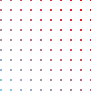

In [22]:
import pandas as pd
from IPython.display import Image, display
import os

s = pd.read_csv('/content/test_summary.csv')
def color(v):
    if pd.isna(v): return 'color: gray'
    return 'color: green' if v else 'color: red; font-weight: bold'
if hasattr(s.style, 'map'):
    display(s.style.map(color, subset=['pass']))
else:
    display(s.style.applymap(color, subset=['pass']))

# 展示 ROI 聚类生成的一张 cluster 图像(可视化确认)
for p in ['/content/OSSpRe/test_cluster']:
    if os.path.isdir(p):
        pngs = sorted(f for f in os.listdir(p) if f.endswith('.png'))
        if pngs:
            print('cluster 图像示例:', pngs[0])
            display(Image(os.path.join(p, pngs[0]), width=300))

## 结果解读

- **全部 PASS**:所有修复在 Linux + gcc/OpenMP + renv 恢复的作者环境 + 真实 Bruker 库下验证通过。
- **bruker_roundtrip SKIP**:Colab 无法访问 Bruker 下载源,不影响其他结论。
- 任何 **FAIL**:查看上方 `run_tests.R` 单元格输出中的 `ERROR:` 行,连同
  `/content/test_summary.csv` 反馈。
- 环境恢复中断:重跑第 2 节的 `Rscript` 单元格即可续传(renv 只补缺失的包)。

## 用真实数据测试(可选)

C++ 与算法层已被上面充分覆盖;`getrefpeak`/`getqlist` 需要真实 Bruker `.d` 数据:

```r
# 将 raw.d 打包为 zip 上传到 /content 后, 在 R 中:
system("cd /content && unzip -q raw.zip")
path <- "/content/raw.d"
getrefpeak(path = path, accept_Bruker_EULA_and_on_Windows_or_Linux = TRUE,
           libpath = "/content/bruker/", batch_size = 100000,
           outref = "refpeak.csv", outcoord = "coord.csv",
           xrange = c(0, 1e9), yrange = c(0, 1e9))
# ...然后按 workflow.Rmd 的步骤继续
```

注意 `workflow.Rmd` 默认 `eval = FALSE`(教程模式),真实数据测试请逐 chunk 运行或将 setup 改为 `eval = TRUE`。